# Self-auditing a video world model: does the sampler cause the over-confidence?

The main run (`wm-selfaudit-full`) used 50 DDIM sampling steps instead of the default 100 to fit in one session. There the model's own disagreement between rollouts came out at about half its real error, so the model looked over-confident. Fewer sampling steps can make rollouts more alike, which would lower disagreement on its own.

**Check.** The first 16 Minecraft clips of the main run (2 batches, all 10 validation videos) are rolled out again 3 times with the default **100 steps** and compared with their 50-step rollouts on exactly the same clips:

- mean real error / mean disagreement (1 = calibrated, above 1 = over-confident),
- bias of disagreement used as a drift estimate with no real data,
- variance gain of the audit's control variate,

with differences bootstrapped over videos, paired by clip.

**Running.** Kaggle, accelerator **GPU T4 x2**, Internet on. Before running, attach the main run's output: *Add Input → Your Work → Notebooks → wm-selfaudit-full*. Its 50-step rollouts are reused and only the 100-step ones are generated (6 jobs, about 4 h). Then *Save Version → Save & Run All*.

## 1. Configuration

In [1]:
import os, re, subprocess, sys, time, shutil, glob, json, threading
import numpy as np

NOTEBOOK_START = time.time()
WORK = "/kaggle/working"
REPO = "/tmp/diffusion-forcing"
DUMP_ROOT = f"{WORK}/wm_audit_data"
RESULTS = f"{WORK}/wm_audit_results"
LOGS = f"{WORK}/generation_logs"
AUDIT = f"{WORK}/wm_audit.py"

N_RUNS = 3
BATCH = 8
GEN_HOURS = 10.5
EPS = 0.1

WANDB_ENTITY = "usmanajmal659-islamia-university-of-bwp"
QUICKSTART_ID = "1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b"

CONDITIONS = {
    "minecraft": dict(label="Minecraft, 50 steps", data="minecraft", dataset="video_minecraft", ckpt="minecraft",
                      patch=32, trained_frames=10, multiplier=2, frame_skip=2, per_video=4, n_clips=40, steps=50,
                      fit_on="minecraft", extra="", prior_min=40),
    "minecraft_steps100": dict(label="Minecraft, 100 steps", data="minecraft", dataset="video_minecraft", ckpt="minecraft",
                               patch=32, trained_frames=10, multiplier=2, frame_skip=2, per_video=4, n_clips=16, steps=100,
                               fit_on="minecraft_steps100", extra="", prior_min=80),
}
REFERENCE = "minecraft"
PRIORITY = [("minecraft_steps100", [0, 1])]


def run(cmd, cwd=None, env=None, log=None, show=None, tail=40, timeout_min=None, prefix=""):
    """Run a shell command in a fresh process; stream selected lines, keep a full log, return the exit code."""
    lines, t0 = [], time.time()
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, text=True, bufsize=1, start_new_session=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    timer = None
    if timeout_min:
        timer = threading.Timer(60 * timeout_min, lambda: (print(f"{prefix}!!! timeout after {timeout_min:.0f} min: stopping",
                                                                 flush=True), os.killpg(p.pid, 9)))
        timer.start()
    fh = open(log, "w") if log else None
    last_beat, last_progress = time.time() - 360, ""
    for line in p.stdout:
        if fh: fh.write(line)
        lines.append(line)
        if "Sampling" in line or "Validation" in line:
            last_progress = line.strip().split("\r")[-1]
        if show is None or any(s in line for s in show):
            print(prefix + line.rstrip()[:400], flush=True)
        elif time.time() - last_beat > 600:
            print(f"{prefix}[{(time.time() - t0) / 60:5.1f} min] {last_progress[:150]}", flush=True)
            last_beat = time.time()
    p.wait()
    if timer: timer.cancel()
    if fh: fh.close()
    if p.returncode != 0 and show is not None:
        print(f"{prefix}--- command failed (exit {p.returncode}); last {tail} lines ---")
        print("".join(lines[-tail:]))
    return p.returncode

print("Python", sys.version.split()[0])
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout)

Python 3.13.15
GPU 0: Tesla T4 (UUID: GPU-b13026d2-9d4c-b250-f5e6-1e646f616de9)
GPU 1: Tesla T4 (UUID: GPU-ac06246c-d7e1-1b82-98ce-8a6bc01d8e21)



## 2. Setup

Clone the official Diffusion Forcing repository, install its requirements and download the pretrained checkpoints with the mini validation sets.

In [2]:
if not os.path.isdir(REPO):
    assert run(f"git clone --depth 1 https://github.com/buoyancy99/diffusion-forcing.git {REPO}") == 0
print("repository:", REPO, subprocess.run(["git", "-C", REPO, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout)

Cloning into '/tmp/diffusion-forcing'...
repository: /tmp/diffusion-forcing 475e0bc



In [3]:
marker = f"{REPO}/.df_requirements_installed"
if not os.path.exists(marker):
    reqs = [l.strip() for l in open(f"{REPO}/requirements.txt") if l.strip() and not l.strip().startswith("#")]
    failed = []
    for r in reqs:
        name = re.split(r"[<>=!~\[ ;]", r)[0].lower()
        if name in {"torch", "torchvision", "torchaudio"}:
            continue
        if subprocess.run([sys.executable, "-m", "pip", "install", "-q", r],
                          capture_output=True, text=True).returncode != 0:
            failed.append(r)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "imageio"], capture_output=True)
    open(marker, "w").write("\n".join(failed))
    print("installed; failed pins:", failed or "none")
else:
    print("requirements already installed; failed pins:", open(marker).read() or "none")

installed; failed pins: none


In [4]:
assert run(f"{sys.executable} -c \"import hydra, omegaconf, lightning, wandb, torch, numpy, scipy, imageio, matplotlib; "
           f"print('torch', torch.__version__, '| numpy', numpy.__version__, '| GPUs:', torch.cuda.device_count())\"",
           cwd=REPO) == 0

/usr/local/lib/python3.13/dist-packages/lightning/fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
torch 2.11.0+cu128 | numpy 2.5.4 | GPUs: 2


In [5]:
if not glob.glob(f"{REPO}/outputs/*.ckpt"):
    assert run(f"gdown {QUICKSTART_ID} -O quickstart_atten.tar.gz && tar -xzf quickstart_atten.tar.gz && rm quickstart_atten.tar.gz",
               cwd=REPO) == 0
ckpts = sorted(glob.glob(f"{REPO}/outputs/*.ckpt"))
print("checkpoints:", [os.path.basename(p) for p in ckpts])

for name, c in list(CONDITIONS.items()):
    c["ckpt_path"] = next((os.path.relpath(p, REPO) for p in ckpts if c["ckpt"] in os.path.basename(p).lower()), None)
    meta_path = f"{REPO}/data/{c['data']}/metadata.json"
    videos = sorted(glob.glob(f"{REPO}/data/{c['data']}/validation/**/*.npz", recursive=True))
    lengths = json.load(open(meta_path))["validation"] if os.path.exists(meta_path) else []
    problem = ("no checkpoint" if not c["ckpt_path"] else "no metadata.json" if not lengths
               else "metadata does not match the videos" if len(lengths) != len(videos) else None)
    if problem:
        print(f"{name}: {problem}, skipped")
        del CONDITIONS[name]
        continue
    c["videos"], c["length"] = len(videos), int(min(lengths))
    print(f"{name}: {c['ckpt_path']}, {len(videos)} validation videos of {c['length']} frames")
assert REFERENCE in CONDITIONS, "the Minecraft checkpoint or data is missing"

Downloading...
From (original): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b
From (redirected): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b&confirm=t&uuid=e4126ca3-445b-461c-b061-e7fb684646e8
To: /tmp/diffusion-forcing/quickstart_atten.tar.gz

  0%|          | 0.00/592M [00:00<?, ?B/s]
  1%|          | 6.82M/592M [00:00<00:13, 43.1MB/s]
  5%|▍         | 27.8M/592M [00:00<00:04, 118MB/s]
  7%|▋         | 41.4M/592M [00:00<00:05, 109MB/s]
 10%|█         | 59.2M/592M [00:00<00:04, 118MB/s]
 14%|█▎        | 81.3M/592M [00:00<00:03, 147MB/s]
 16%|█▋        | 97.0M/592M [00:00<00:03, 131MB/s]
 20%|█▉        | 118M/592M [00:00<00:03, 152MB/s]
 23%|██▎       | 135M/592M [00:00<00:02, 155MB/s]
 26%|██▌       | 152M/592M [00:01<00:02, 152MB/s]
 30%|██▉       | 177M/592M [00:01<00:02, 181MB/s]
 34%|███▍      | 201M/592M [00:01<00:01, 198MB/s]
 38%|███▊      | 226M/592M [00:01<00:01, 213MB/s]
 42%|████▏     | 249M/592M [00:01<00:01, 210MB/s]
 46%|████▋     

## 3. Code

`df_dump_run.py` runs the repository's validation unchanged on a fixed list of clips and saves the raw predicted and real videos. `wm_audit.py` implements the estimators, statistics and figures, followed by its self-tests.

In [6]:
%%writefile /tmp/diffusion-forcing/df_dump_run.py
"""Run Diffusion Forcing's `python -m main ...` unchanged on a fixed list of validation clips, and save the raw float predictions and real videos that the repo passes to its video logger (utils.logging_utils.log_video)."""
import json
import os
import runpy
import sys

import numpy as np

sys.path.insert(0, os.getcwd())
OUT = os.environ["DF_DUMP_FILE"]
CLIPS = json.loads(os.environ["DF_CLIPS"])
os.makedirs(os.path.dirname(OUT), exist_ok=True)

import datasets.video.base_video_dataset as bv
import utils.logging_utils as lu

if not hasattr(lu, "log_video"):
    raise SystemExit("utils.logging_utils.log_video not found: the repository layout changed.")
_original_log = lu.log_video
_original_init = bv.BaseVideoDataset.__init__


def init_with_fixed_clips(self, cfg, split="training"):
    """Put the requested (video, start frame) windows first in the validation order."""
    _original_init(self, cfg, split)
    if split == "training":
        return
    first = np.concatenate([[0], self.cum_clips_per_video[:-1]])
    chosen = []
    for v, s in CLIPS:
        if v >= len(first) or s >= self.clips_per_video[v]:
            raise SystemExit(f"clip (video {v}, start {s}) is not in the {split} set "
                             f"({len(first)} videos, window of {self.n_frames} frames)")
        chosen.append(int(first[v] + s))
    taken = set(chosen)
    self.idx_remap = chosen + [i for i in self.idx_remap if i not in taken]


def _to_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().float().cpu().numpy()
    return np.asarray(x, dtype=np.float32)


def log_video_and_dump(*args, **kwargs):
    named = [kwargs.get("observation_hat"), kwargs.get("observation_gt")]
    arrays = [a for a in list(args) + named if a is not None and len(getattr(a, "shape", ())) == 5]
    if len(arrays) >= 2 and not os.path.exists(OUT):
        pred, gt = _to_numpy(arrays[0]), _to_numpy(arrays[1])
        tmp = OUT[:-4] + ".part.npz"
        np.savez_compressed(tmp, pred=pred.astype(np.float16), gt=gt.astype(np.float16),
                            clips=np.array(CLIPS[:pred.shape[1]], dtype=np.int64))
        os.replace(tmp, OUT)
        print(f"[dump] saved {OUT} with shape {pred.shape}", flush=True)
    return _original_log(*args, **kwargs)


bv.BaseVideoDataset.__init__ = init_with_fixed_clips
lu.log_video = log_video_and_dump
sys.argv = ["main.py"] + sys.argv[1:]
runpy.run_module("main", run_name="__main__", alter_sys=True)

Writing /tmp/diffusion-forcing/df_dump_run.py


In [7]:
%%writefile /kaggle/working/wm_audit.py
"""Self-auditing a video world model with sparse real observations."""
import argparse
import glob
import json
import os

import numpy as np

FEATURES_VISUAL = ["texture", "motion", "time"]
FEATURES_ALL = ["disagreement", "texture", "motion", "time"]
FEATURES_PAIR = ["disagreement_pair", "texture", "motion", "time"]

BASE = "Uniform (Horvitz-Thompson)"
VISUAL = "Smart + CV[visual]"
BEST = "Smart + CV[visual+disagreement]"
PAIR = "Smart + CV[visual+disagreement], 2 rollouts"
ORACLE = "Oracle Neyman (not deployable)"
SELF_DIS = "Rollout disagreement"
SELF_CAL = "Calibrated predictor (visual+disagreement)"
SELF_VIS = "Visual predictor"
BIN_LABELS = {"all": "all imagined frames", "within": "within trained length", "beyond": "beyond trained length"}


def to_thwc(a):
    """Dumps are (time, batch, channel, height, width); return (batch, time, height, width, channel) in [0, 1]."""
    return np.clip(np.asarray(a, np.float32).transpose(1, 0, 3, 4, 2), 0.0, 1.0)


def load_condition(cdir):
    """Clips of one condition that exist in every run: dict(video, start, gt, preds)."""
    rdirs = sorted(glob.glob(os.path.join(cdir, "run_*")))
    have = [{os.path.basename(f) for f in glob.glob(os.path.join(r, "batch_*.npz"))} for r in rdirs]
    rdirs, have = [r for r, h in zip(rdirs, have) if h], [h for h in have if h]
    if not rdirs:
        return [], 0, 0
    clips, dropped = [], 0
    for name in sorted(set.intersection(*have)):
        zs = [np.load(os.path.join(r, name)) for r in rdirs]
        gts = [to_thwc(z["gt"]) for z in zs]
        preds = [to_thwc(z["pred"]) for z in zs]
        ids = zs[0]["clips"]
        for i in range(gts[0].shape[0]):
            g = gts[0][i]
            if any(float(((g - x[i]) ** 2).mean()) > 1e-5 for x in gts[1:]):
                raise SystemExit(f"{cdir}/{name}: clip {i} has a different real video in different runs")
            if (g.reshape(g.shape[0], -1).max(1) == 0).any():
                dropped += 1
                continue
            clips.append(dict(video=int(ids[i][0]), start=int(ids[i][1]), gt=g, preds=[p[i] for p in preds]))
    return clips, len(rdirs), dropped


def context_frames(clips, tol=1e-6):
    """Number of leading frames copied from the real video (prediction == real) in every clip/run."""
    n = min(c["gt"].shape[0] for c in clips)
    for t in range(n):
        for c in clips:
            for p in c["preds"]:
                if float(((p[t] - c["gt"][t]) ** 2).mean()) > tol:
                    return t
    return n


def patchify(x, P):
    T, H, W, C = x.shape
    H2, W2 = (H // P) * P, (W // P) * P
    x = x[:, :H2, :W2]
    return x.reshape(T, H2 // P, P, W2 // P, P, C).transpose(0, 1, 3, 2, 4, 5).reshape(T, (H2 // P) * (W2 // P), -1)


def build_units(clips, P, n_ctx):
    """One unit = (clip, run). Arrays over imagined frames t >= n_ctx: e[t,j] true patch error, label-free features."""
    units = []
    R = len(clips[0]["preds"])
    for ci, c in enumerate(clips):
        gt_p = patchify(c["gt"], P)
        pr_p = [patchify(p, P) for p in c["preds"]]
        T, J = gt_p.shape[:2]
        tt = np.repeat(((np.arange(T) - n_ctx + 1) / max(T - n_ctx, 1))[:, None], J, 1)
        sl = slice(n_ctx, T)
        for r in range(R):
            g = pr_p[r]
            mot = np.zeros((T, J), np.float32)
            mot[1:] = ((g[1:] - g[:-1]) ** 2).mean(-1)
            f = dict(texture=g.var(-1), motion=mot, time=tt)
            if R > 1:
                f["disagreement"] = np.mean([((g - pr_p[s]) ** 2).mean(-1) for s in range(R) if s != r], axis=0)
                f["disagreement_pair"] = ((g - pr_p[(r + 1) % R]) ** 2).mean(-1)
            e = ((g - gt_p) ** 2).mean(-1)
            units.append(dict(clip=ci, run=r, video=c["video"], e=e[sl].astype(np.float64),
                              f={k: np.asarray(v[sl], np.float64) for k, v in f.items()}))
    return units


def design(u, names):
    cols = [u["f"][n].ravel() for n in names] + [np.ones(u["e"].size)]
    return np.stack(cols, 1)


def fit_models(train, names, ridge=1e-8):
    """Least-squares mean model for e, and a second-moment model for the residual (for sampling)."""
    X = np.concatenate([design(u, names) for u in train])
    y = np.concatenate([u["e"].ravel() for u in train])
    sc = X.std(0)
    sc[sc == 0] = 1.0
    Xs = X / sc
    A = Xs.T @ Xs + ridge * np.eye(Xs.shape[1])
    w = np.linalg.solve(A, Xs.T @ y) / sc
    r2 = (y - X @ w) ** 2
    v = np.linalg.solve(A, Xs.T @ r2) / sc
    return w, v


def frame_estimates(e_t, mu_t, q_t):
    """All J possible single-patch estimates of the frame-mean error at one frame."""
    J = e_t.size
    return mu_t.mean() + (e_t - mu_t) / (J * q_t)


def exact_relvar(e, mu, q, k=1):
    """Exact relative variance of the rollout-mean estimate with k independent patches per frame."""
    T = e.shape[0]
    var = 0.0
    for t in range(T):
        est = frame_estimates(e[t], mu[t], q[t])
        var += float((q[t] * (est - e[t].mean()) ** 2).sum())
    var /= (k * T * T)
    return var / float(e.mean()) ** 2


def exact_bias(e, mu, q):
    out = 0.0
    for t in range(e.shape[0]):
        out += float((q[t] * frame_estimates(e[t], mu[t], q[t])).sum() - e[t].mean())
    return out / e.shape[0]


def sampling_from_m2(m2, eps):
    s = np.sqrt(np.clip(m2, 1e-12, None))
    q = s / s.sum(1, keepdims=True)
    return (1 - eps) * q + eps / q.shape[1]


def shuffle_within_frames(u, names, rng):
    perm = np.argsort(rng.random(u["e"].shape), axis=1)
    return dict(e=u["e"], f={n: np.take_along_axis(u["f"][n], perm, 1) for n in names})


def method_plan(units, pool, eps, seed=0):
    """(mu, q) of every audit and the label-free self-assessments, for every unit.
    Predictors are fit on `pool` leaving out every unit of the test unit's video."""
    rng = np.random.default_rng(seed)
    feats = {"visual": FEATURES_VISUAL}
    if "disagreement" in units[0]["f"] and "disagreement" in pool[0]["f"]:
        feats["all"] = FEATURES_ALL
        if 1 + max(u["run"] for u in units) > 2 and "disagreement_pair" in pool[0]["f"]:
            feats["pair"] = FEATURES_PAIR
    plans, selfs = {}, {}
    for v in sorted({u["video"] for u in units}):
        train = [u for u in pool if u["video"] != v]
        if not train:
            raise SystemExit("Leave-one-video-out fitting needs clips from at least 2 videos.")
        models = {k: fit_models(train, names) for k, names in feats.items()}
        models["shuffled"] = fit_models([shuffle_within_frames(u, FEATURES_VISUAL, rng) for u in train], FEATURES_VISUAL)
        for u in units:
            if u["video"] != v:
                continue
            shp = u["e"].shape
            uni = np.full(shp, 1.0 / shp[1])
            mu, m2 = {}, {}
            for k, (w, s) in models.items():
                src = shuffle_within_frames(u, FEATURES_VISUAL, rng) if k == "shuffled" else u
                X = design(src, feats.get(k, FEATURES_VISUAL))
                mu[k], m2[k] = (X @ w).reshape(shp), (X @ s).reshape(shp)
            p = {BASE: (np.zeros(shp), uni),
                 "Uniform + CV[visual]": (mu["visual"], uni),
                 VISUAL: (mu["visual"], sampling_from_m2(m2["visual"], eps)),
                 "Negative control: CV[shuffled proxies]": (mu["shuffled"], uni)}
            sa = {SELF_VIS: mu["visual"]}
            if "all" in mu:
                p["Uniform + CV[visual+disagreement]"] = (mu["all"], uni)
                p[BEST] = (mu["all"], sampling_from_m2(m2["all"], eps))
                if "pair" in mu:
                    p[PAIR] = (mu["pair"], sampling_from_m2(m2["pair"], eps))
                sa[SELF_DIS] = u["f"]["disagreement"]
                sa[SELF_CAL] = mu["all"]
            best = mu.get("all", mu["visual"])
            p[ORACLE] = (best, sampling_from_m2((u["e"] - best) ** 2, eps))
            plans[(u["clip"], u["run"])] = p
            selfs[(u["clip"], u["run"])] = sa
    return plans, selfs


def horizon_bins(n_eval, n_inside):
    bins = {"all": slice(0, n_eval)}
    if 0 < n_inside < n_eval:
        bins["within"] = slice(0, n_inside)
        bins["beyond"] = slice(n_inside, n_eval)
    return bins


def evaluate(units, plans, selfs, sl):
    """Exact relative variance and bias of every audit, and relative error of every self-assessment, on frames `sl`."""
    n = len(units)
    rv, bias, se = {}, {}, {}
    for i, u in enumerate(units):
        key = (u["clip"], u["run"])
        e = u["e"][sl]
        truth = float(e.mean())
        for m, (mu, q) in plans[key].items():
            rv.setdefault(m, np.zeros(n))[i] = exact_relvar(e, mu[sl], q[sl])
            bias[m] = max(bias.get(m, 0.0), abs(exact_bias(e, mu[sl], q[sl])) / truth)
        for m, est in selfs[key].items():
            se.setdefault(m, np.zeros(n))[i] = (float(est[sl].mean()) - truth) / truth
    return dict(rv=rv, bias=bias, self_err=se)


def cluster_sets(groups, B=5000, seed=1):
    """Bootstrap resamples of whole videos: windows of one video are not independent."""
    rng = np.random.default_rng(seed)
    g = np.asarray(groups)
    members = [np.flatnonzero(g == k) for k in np.unique(g)]
    return [np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))]) for _ in range(B)]


def ci(stat, sets):
    s = np.array([stat(x) for x in sets])
    return float(np.quantile(s, 0.025)), float(np.quantile(s, 0.975))


def audit_rows(ev, sets, k=1):
    rv, n = ev["rv"], len(next(iter(ev["rv"].values())))
    full = np.arange(n)
    rows = []
    for m in rv:
        rel = lambda s, m=m: 100 * np.sqrt(rv[m][s].mean() / k)
        ratio = lambda s, m=m: rv[m][s].mean() / rv[BASE][s].mean()
        lo, hi = ci(rel, sets)
        rlo, rhi = ci(ratio, sets)
        r = ratio(full)
        rows.append(dict(method=m, rel_rmse_pct=rel(full), ci_lo=lo, ci_hi=hi, var_ratio=r, ratio_lo=rlo,
                         ratio_hi=rhi, budget_equiv=1 / r, max_abs_bias_pct=100 * ev["bias"][m]))
    return rows


def self_rows(ev, sets):
    rows = []
    for m, err in ev["self_err"].items():
        full = np.arange(len(err))
        bias = lambda s, err=err: 100 * err[s].mean()
        rmse = lambda s, err=err: 100 * np.sqrt((err[s] ** 2).mean())
        blo, bhi = ci(bias, sets)
        lo, hi = ci(rmse, sets)
        rows.append(dict(method=m, bias_pct=bias(full), bias_lo=blo, bias_hi=bhi, rel_rmse_pct=rmse(full),
                         ci_lo=lo, ci_hi=hi))
    return rows


def calibration(units, sl, sets):
    """How well the model's own disagreement matches its real error: slope of error on disagreement through the origin."""
    from scipy.stats import spearmanr
    E = [u["e"][sl] for u in units]
    D = [u["f"]["disagreement"][sl] for u in units]
    sED = np.array([(e * d).sum() for e, d in zip(E, D)])
    sDD = np.array([(d * d).sum() for d in D])
    sE, sD = np.array([e.sum() for e in E]), np.array([d.sum() for d in D])
    slope = lambda s: sED[s].sum() / sDD[s].sum()
    ratio = lambda s: sE[s].sum() / sD[s].sum()
    full = np.arange(len(units))
    lo, hi = ci(slope, sets)
    rlo, rhi = ci(ratio, sets)
    rho = float(spearmanr(np.concatenate([e.ravel() for e in E]), np.concatenate([d.ravel() for d in D]))[0])
    return dict(slope=float(slope(full)), slope_lo=lo, slope_hi=hi, error_over_disagreement=float(ratio(full)),
                ratio_lo=rlo, ratio_hi=rhi, spearman=rho)


def compute_frontier(ev, sets, ks=(1, 2, 3, 4)):
    """Real patches per frame versus extra rollouts: what each costs and what it buys."""
    rv = ev["rv"]
    lines = [("1 rollout, uniform", BASE, 1), ("1 rollout, smart + CV[visual]", VISUAL, 1),
             ("2 rollouts, smart + CV[visual+disagreement]", PAIR, 2),
             ("3 rollouts, smart + CV[visual+disagreement]", BEST, 3)]
    full = np.arange(len(rv[BASE]))
    out = []
    for label, m, nroll in lines:
        if m not in rv:
            continue
        for k in ks:
            rel = lambda s, m=m, k=k: 100 * np.sqrt(rv[m][s].mean() / k)
            lo, hi = ci(rel, sets)
            out.append(dict(config=label, method=m, rollouts=nroll, patches=k, rel_rmse_pct=rel(full), ci_lo=lo, ci_hi=hi))
    head = {}
    if BEST in rv:
        eq = lambda s: rv[VISUAL][s].mean() / rv[BEST][s].mean()
        lo, hi = ci(eq, sets)
        head["patches_equiv_3_rollouts"] = dict(value=float(eq(full)), ci_lo=lo, ci_hi=hi)
        r = lambda s: rv[BEST][s].mean() / (rv[VISUAL][s].mean() / 2)
        lo, hi = ci(r, sets)
        head["var_3r1p_over_1r2p"] = dict(value=float(r(full)), ci_lo=lo, ci_hi=hi)
    return out, head


def mc_check(u, plan, rng, reps=2000):
    out = {}
    Tn, Jn = u["e"].shape
    truth = u["e"].mean()
    for m, (mu, q) in plan.items():
        est = np.zeros(reps)
        for t in range(Tn):
            est += frame_estimates(u["e"][t], mu[t], q[t])[rng.choice(Jn, size=reps, p=q[t])]
        est /= Tn
        out[m] = dict(mc_bias_pct=float(100 * (est.mean() - truth) / truth),
                      mc_relrmse_pct=float(100 * np.sqrt(((est - truth) ** 2).mean()) / truth),
                      exact_relrmse_pct=float(100 * np.sqrt(exact_relvar(u["e"], mu, q))))
    return out


def md_table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    return "\n".join(lines)


def analyze(data_root, out, eps=0.1, mc_reps=2000, B=5000):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    ref = plan["reference"]
    conds = {}
    for name, cfg in plan["conditions"].items():
        clips, R, dropped = load_condition(os.path.join(data_root, name))
        n_videos = len({c["video"] for c in clips})
        if n_videos < 3:
            print(f"{name}: {len(clips)} clips from {n_videos} videos; need at least 3 videos, skipped")
            continue
        n_ctx = context_frames(clips)
        T, H, W, _ = clips[0]["gt"].shape
        P = cfg["patch"]
        units = build_units(clips, P, n_ctx)
        conds[name] = dict(cfg=cfg, clips=clips, units=units, R=R, n_ctx=n_ctx, T=T, H=H, W=W, P=P,
                           J=(H // P) * (W // P), videos=n_videos,
                           bins=horizon_bins(T - n_ctx, cfg["trained_frames"] - n_ctx))
        print(f"{name}: {len(clips)} clips from {n_videos} videos x {R} runs, {T} frames ({n_ctx} context), "
              f"{H}x{W}, patch {P} -> J={conds[name]['J']}" + (f", {dropped} padded clips dropped" if dropped else ""))
    if ref not in conds:
        raise SystemExit(f"The reference condition '{ref}' has no usable data.")

    report, summary = [], dict(eps=eps, conditions={})
    for name, c in conds.items():
        fit_on = c["cfg"].get("fit_on", name)
        if fit_on not in conds:
            print(f"{name}: predictors are fit on '{fit_on}', which has no data; skipped")
            continue
        units = c["units"]
        pool = conds[fit_on]["units"]
        c["plans"], c["selfs"] = method_plan(units, pool, eps)
        sets = cluster_sets([u["video"] for u in units], B=B)
        c["ev"] = {b: evaluate(units, c["plans"], c["selfs"], sl) for b, sl in c["bins"].items()}
        s = dict(label=c["cfg"]["label"], fit_on=fit_on, clips=len(c["clips"]), videos=c["videos"], runs=c["R"],
                 frames=c["T"], context=c["n_ctx"], patch=c["P"], patches_per_frame=c["J"],
                 bins={b: [sl.start + 1, sl.stop] for b, sl in c["bins"].items()},
                 audits={b: audit_rows(ev, sets) for b, ev in c["ev"].items()},
                 self_assessment={b: self_rows(ev, sets) for b, ev in c["ev"].items()})
        if c["R"] > 1:
            s["calibration"] = {b: calibration(units, sl, sets) for b, sl in c["bins"].items()}
            Eall = np.concatenate([u["e"].ravel() for u in units])
            from scipy.stats import spearmanr
            s["proxy_spearman"] = {n: float(spearmanr(Eall, np.concatenate([u["f"][n].ravel() for u in units]))[0])
                                   for n in FEATURES_ALL}
        if c["R"] > 2:
            s["compute"], s["compute_headline"] = compute_frontier(c["ev"]["all"], sets)
        drift = np.array([[((p - x["gt"]) ** 2).mean(axis=(1, 2, 3)) for p in x["preds"]] for x in c["clips"]])
        s["drift_mean_per_frame"] = drift.mean(axis=(0, 1)).tolist()
        c["drift"] = drift
        if c["R"] > 1:
            c["dis_curve"] = np.array([[np.mean([((x["preds"][r] - x["preds"][q]) ** 2).mean(axis=(1, 2, 3))
                                                 for q in range(c["R"]) if q != r], axis=0) for r in range(c["R"])]
                                       for x in c["clips"]])
        if name == ref:
            u0 = units[0]
            s["mc_check"] = mc_check(u0, c["plans"][(u0["clip"], u0["run"])], np.random.default_rng(7), mc_reps)
        summary["conditions"][name] = s
    done = [n for n in conds if "ev" in conds[n]]

    for name in done:
        c, s = conds[name], summary["conditions"][name]
        rows = s["audits"]["all"]
        report.append(f"## {s['label']}\n\n{s['clips']} clips from {s['videos']} videos x {s['runs']} rollouts; "
                      f"{s['frames'] - s['context']} imagined frames after {s['context']} real context frames; "
                      f"{s['patches_per_frame']} patches per frame, 1 inspected. Predictors fit on "
                      f"'{conds[s['fit_on']]['cfg']['label']}', leaving the evaluated video out. "
                      f"95% CIs resample whole videos.\n")
        report.append(md_table(["Audit (1 real patch per frame)", "Relative error (%)", "95% CI", "Variance vs uniform",
                                "95% CI", "Equivalent budget", "Max bias (%)"],
                               [[r["method"], f"{r['rel_rmse_pct']:.1f}", f"{r['ci_lo']:.1f}-{r['ci_hi']:.1f}",
                                 f"{r['var_ratio']:.2f}", f"{r['ratio_lo']:.2f}-{r['ratio_hi']:.2f}",
                                 f"x{r['budget_equiv']:.2f}", f"{r['max_abs_bias_pct']:.1e}"] for r in rows]) + "\n")
        sr = []
        for b in c["bins"]:
            best = next((r for r in s["audits"][b] if r["method"] == BEST),
                        next(r for r in s["audits"][b] if r["method"] == VISUAL))
            for r in s["self_assessment"][b]:
                sr.append([BIN_LABELS[b], r["method"] + " (no real data)", f"{r['bias_pct']:+.1f} ({r['bias_lo']:+.1f} to {r['bias_hi']:+.1f})",
                           f"{r['rel_rmse_pct']:.1f} ({r['ci_lo']:.1f}-{r['ci_hi']:.1f})"])
            sr.append([BIN_LABELS[b], f"Audit: {best['method']}, 1 patch", "0 (exact)",
                       f"{best['rel_rmse_pct']:.1f} ({best['ci_lo']:.1f}-{best['ci_hi']:.1f})"])
        report.append("**Self-assessment versus audit**\n\n" + md_table(
            ["Frames", "Estimator", "Signed bias (%) [95% CI]", "Relative error (%) [95% CI]"], sr) + "\n")
        if "calibration" in s:
            report.append("**Calibration of the model's disagreement** (slope of real error on disagreement; "
                          "1 = calibrated, >1 = over-confident)\n\n" + md_table(
                ["Frames", "Slope", "95% CI", "Mean error / mean disagreement", "95% CI", "Spearman"],
                [[BIN_LABELS[b], f"{k['slope']:.2f}", f"{k['slope_lo']:.2f}-{k['slope_hi']:.2f}",
                  f"{k['error_over_disagreement']:.2f}", f"{k['ratio_lo']:.2f}-{k['ratio_hi']:.2f}", f"{k['spearman']:.2f}"]
                 for b, k in s["calibration"].items()]) + "\n")
        if "compute" in s:
            ks = sorted({r["patches"] for r in s["compute"]})
            cfgs = list(dict.fromkeys(r["config"] for r in s["compute"]))
            report.append("**Rollouts versus real patches** (relative error %, all imagined frames)\n\n" + md_table(
                ["Configuration"] + [f"{k} patch{'es' if k > 1 else ''}/frame" for k in ks],
                [[cf] + [next(f"{r['rel_rmse_pct']:.1f} ({r['ci_lo']:.1f}-{r['ci_hi']:.1f})" for r in s["compute"]
                              if r["config"] == cf and r["patches"] == k) for k in ks] for cf in cfgs]) + "\n")
        report.append("")

    rs = summary["conditions"][ref]
    notes = []
    for r in rs["audits"]["all"]:
        if r["method"] in (BASE, ORACLE):
            continue
        notes.append(f"- **{r['method']}**: variance x{r['var_ratio']:.2f} of uniform (95% CI {r['ratio_lo']:.2f}-"
                     f"{r['ratio_hi']:.2f}), the accuracy of {r['budget_equiv']:.2f} uniform patches per frame. "
                     + ("Reduction is statistically clear." if r["ratio_hi"] < 1 else "Not distinguishable from uniform."))
    if "compute_headline" in rs and rs["compute_headline"]:
        h = rs["compute_headline"]
        e, v = h["patches_equiv_3_rollouts"], h["var_3r1p_over_1r2p"]
        notes.append(f"- **Rollouts versus patches**: with 3 rollouts and 1 patch per frame the audit is as accurate as a "
                     f"single-rollout audit with {e['value']:.2f} patches per frame (95% CI {e['ci_lo']:.2f}-{e['ci_hi']:.2f}). "
                     f"Variance of 3 rollouts + 1 patch relative to 1 rollout + 2 patches: {v['value']:.2f} "
                     f"({v['ci_lo']:.2f}-{v['ci_hi']:.2f}).")
    for name in done:
        s = summary["conditions"][name]
        for b, rows in s["self_assessment"].items():
            for r in rows:
                if r["method"] == SELF_VIS:
                    continue
                sig = r["bias_hi"] < 0 or r["bias_lo"] > 0
                notes.append(f"- **{s['label']}, {BIN_LABELS[b]}, {r['method']}**: bias {r['bias_pct']:+.1f}% "
                             f"({r['bias_lo']:+.1f} to {r['bias_hi']:+.1f}), "
                             + ("CI excludes zero." if sig else "CI includes zero."))
    notes.append("- **Unbiasedness**: the exact expectation of every audit equals the truth to numerical precision "
                 "(max bias column), in every condition and horizon, including the negative control.")
    md = "\n".join(report) + "\n## Findings\n\n" + "\n".join(notes) + "\n"
    open(os.path.join(out, "results.md"), "w").write(md)
    json.dump(summary, open(os.path.join(out, "summary.json"), "w"), indent=2)
    with open(os.path.join(out, "per_unit.csv"), "w") as f:
        f.write("condition,frames,estimator,clip,run,video,start,relative_variance,relative_error\n")
        for name in done:
            c = conds[name]
            for b, ev in c["ev"].items():
                for i, u in enumerate(c["units"]):
                    st = c["clips"][u["clip"]]["start"]
                    for m, v in ev["rv"].items():
                        f.write(f"{name},{b},{m},{u['clip']},{u['run']},{u['video']},{st},{v[i]:.6g},\n")
                    for m, v in ev["self_err"].items():
                        f.write(f"{name},{b},{m},{u['clip']},{u['run']},{u['video']},{st},,{v[i]:.6g}\n")

    fig, axs = plt.subplots(1, len(done), figsize=(5.2 * len(done), 3.8), squeeze=False)
    for a, name in zip(axs[0], done):
        c = conds[name]
        T, n_ctx, C = c["T"], c["n_ctx"], len(c["clips"])
        tt = np.arange(T) - n_ctx + 1
        for row in c["drift"].reshape(-1, T):
            a.plot(tt, row, color="0.8", lw=0.6)
        vids = np.array([x["video"] for x in c["clips"]])
        sets = cluster_sets(vids, B=1000, seed=3)
        boot = np.array([c["drift"][s].mean(axis=(0, 1)) for s in sets])
        a.plot(tt, c["drift"].mean(axis=(0, 1)), color="C0", lw=2.2, label=f"real error, {C} clips x {c['R']} rollouts")
        a.fill_between(tt, np.quantile(boot, .025, 0), np.quantile(boot, .975, 0), color="C0", alpha=.25)
        if "dis_curve" in c:
            a.plot(tt, c["dis_curve"].mean(axis=(0, 1)), "--", color="C3", lw=2, label="model's own disagreement")
        a.axvline(0.5, color="k", ls=":", lw=1)
        if "beyond" in c["bins"]:
            a.axvline(c["bins"]["beyond"].start + 0.5, color="0.4", ls="--", lw=1, label="trained sequence length")
        a.set_title(c["cfg"]["label"], fontsize=10)
        a.set_xlabel("frames after the last real context frame")
        a.grid(alpha=.3)
        a.legend(fontsize=7)
    axs[0][0].set_ylabel("full-frame MSE")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig1_drift.png"), dpi=150)
    plt.close(fig)

    with_cal = [n for n in done if "calibration" in summary["conditions"][n]]
    if with_cal:
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
        units = conds[ref]["units"]
        E = np.concatenate([u["e"].ravel() for u in units])
        D = np.concatenate([u["f"]["disagreement"].ravel() for u in units])
        edges = np.quantile(D, np.linspace(0, 1, 11))
        idx = np.clip(np.digitize(D, edges[1:-1]), 0, 9)
        a1.scatter(D, E, s=2, alpha=.1, color="0.5", label="patches")
        a1.plot([D[idx == b].mean() for b in range(10)], [E[idx == b].mean() for b in range(10)], "o-", color="C3",
                label="binned mean")
        lim = [0, float(max(np.quantile(D, .99), np.quantile(E, .99)))]
        a1.plot(lim, lim, "k--", lw=1, label="calibrated (y = x)")
        a1.set_xlim(lim)
        a1.set_ylim(lim)
        a1.set_xlabel("disagreement between rollouts (label-free)")
        a1.set_ylabel("true patch error")
        a1.set_title(f"{conds[ref]['cfg']['label']} (Spearman {summary['conditions'][ref]['calibration']['all']['spearman']:.2f})",
                     fontsize=10)
        a1.legend(fontsize=7)
        a1.grid(alpha=.3)
        x, labels = 0, []
        for i, name in enumerate(with_cal):
            for b, k in summary["conditions"][name]["calibration"].items():
                a2.errorbar(x, k["slope"], yerr=[[k["slope"] - k["slope_lo"]], [k["slope_hi"] - k["slope"]]], fmt="o",
                            color=f"C{i}", capsize=3)
                labels.append(f"{conds[name]['cfg']['label']}\n{BIN_LABELS[b]}")
                x += 1
        a2.axhline(1, color="k", ls="--", lw=1)
        a2.set_xticks(range(x), labels, fontsize=7, rotation=30, ha="right")
        a2.set_ylabel("calibration slope (real error / disagreement)")
        a2.set_title("Above 1: the model is over-confident", fontsize=10)
        a2.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig2_calibration.png"), dpi=150)
        plt.close(fig)

    rows = rs["audits"]["all"]
    order = [r for r in rows if r["method"] != ORACLE] + [r for r in rows if r["method"] == ORACLE]
    fig, ax = plt.subplots(figsize=(8, 0.5 + 0.5 * len(order)))
    y = np.arange(len(order))[::-1]
    for yi, r in zip(y, order):
        col = "0.6" if r["method"].startswith(("Oracle", "Negative")) else ("C3" if "disagreement" in r["method"] else "C0")
        ax.barh(yi, r["rel_rmse_pct"], color=col)
        ax.errorbar(r["rel_rmse_pct"], yi, xerr=[[r["rel_rmse_pct"] - r["ci_lo"]], [r["ci_hi"] - r["rel_rmse_pct"]]],
                    color="k", capsize=3)
    ax.set_yticks(y, [r["method"] for r in order], fontsize=8)
    ax.set_xlabel("relative error of the drift audit (%), 1 patch per frame; lower is better")
    ax.set_title(f"{rs['label']}: auditing drift from one real patch per frame (95% CI over videos)", fontsize=10)
    ax.grid(axis="x", alpha=.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig3_estimators.png"), dpi=150)
    plt.close(fig)

    groups = [(n, b) for n in done for b in conds[n]["bins"]]
    shown = [SELF_DIS, SELF_CAL]
    if any(r["method"] in shown for n, b in groups for r in summary["conditions"][n]["self_assessment"][b]):
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(max(7, 1.6 * len(groups)), 6.5), sharex=True)
        w = 0.26
        for gi, (n, b) in enumerate(groups):
            s = summary["conditions"][n]
            for mi, m in enumerate(shown):
                r = next((r for r in s["self_assessment"][b] if r["method"] == m), None)
                if r is None:
                    continue
                xpos = gi + (mi - 1) * w
                a1.bar(xpos, r["bias_pct"], w, color=f"C{mi + 1}", label=m + " (no real data)" if gi == 0 else None)
                a1.errorbar(xpos, r["bias_pct"], yerr=[[r["bias_pct"] - r["bias_lo"]], [r["bias_hi"] - r["bias_pct"]]],
                            color="k", capsize=2)
                a2.bar(xpos, r["rel_rmse_pct"], w, color=f"C{mi + 1}")
                a2.errorbar(xpos, r["rel_rmse_pct"], yerr=[[r["rel_rmse_pct"] - r["ci_lo"]], [r["ci_hi"] - r["rel_rmse_pct"]]],
                            color="k", capsize=2)
            best = next((r for r in s["audits"][b] if r["method"] == BEST), None)
            if best:
                xpos = gi + w
                a1.bar(xpos, 0, w, color="C0", label="audit, 1 real patch per frame" if gi == 0 else None)
                a1.plot(xpos, 0, "D", color="C0")
                a2.bar(xpos, best["rel_rmse_pct"], w, color="C0")
                a2.errorbar(xpos, best["rel_rmse_pct"], yerr=[[best["rel_rmse_pct"] - best["ci_lo"]],
                                                              [best["ci_hi"] - best["rel_rmse_pct"]]], color="k", capsize=2)
        a1.axhline(0, color="k", lw=0.8)
        a1.set_ylabel("signed bias of the drift estimate (%)")
        a1.legend(fontsize=7)
        a1.grid(axis="y", alpha=.3)
        a2.set_ylabel("relative error (%)")
        a2.set_xticks(range(len(groups)), [f"{conds[n]['cfg']['label']}\n{BIN_LABELS[b]}" for n, b in groups], fontsize=7)
        a2.grid(axis="y", alpha=.3)
        a1.set_title("Label-free self-assessment versus the audit with 1 real patch per frame", fontsize=10)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig4_self_assessment.png"), dpi=150)
        plt.close(fig)

    if "compute" in rs:
        fig, ax = plt.subplots(figsize=(6.2, 3.8))
        for i, cf in enumerate(dict.fromkeys(r["config"] for r in rs["compute"])):
            pts = [r for r in rs["compute"] if r["config"] == cf]
            k = np.array([r["patches"] for r in pts])
            ax.plot(k, [r["rel_rmse_pct"] for r in pts], "o-", color=f"C{i}", label=cf)
            ax.fill_between(k, [r["ci_lo"] for r in pts], [r["ci_hi"] for r in pts], color=f"C{i}", alpha=.12)
        ax.set_xlabel("real patches inspected per frame")
        ax.set_ylabel("relative error (%)")
        ax.set_title(f"{rs['label']}: extra rollouts versus extra real patches", fontsize=10)
        ax.set_xticks(sorted({r["patches"] for r in rs["compute"]}))
        ax.grid(alpha=.3)
        ax.legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig5_compute.png"), dpi=150)
        plt.close(fig)

    c = conds[ref]
    ci_, ri = np.unravel_index(np.argmax(c["drift"][:, :, -1]), c["drift"].shape[:2])
    x = c["clips"][ci_]
    t = c["n_ctx"] + (c["T"] - c["n_ctx"]) // 2
    u = next(v for v in c["units"] if v["clip"] == ci_ and v["run"] == ri)
    m = BEST if BEST in c["plans"][(ci_, ri)] else VISUAL
    q = c["plans"][(ci_, ri)][m][1][t - c["n_ctx"]]
    gh, gw = c["H"] // c["P"], c["W"] // c["P"]
    panels = [("real (evaluator only)", x["gt"][t]), ("imagined by the model", x["preds"][ri][t]),
              ("true error", ((x["preds"][ri][t] - x["gt"][t]) ** 2).mean(-1))]
    if "disagreement" in u["f"]:
        panels.append(("disagreement (label-free)", u["f"]["disagreement"][t - c["n_ctx"]].reshape(gh, gw)))
    panels.append(("where the audit looks (q)", q.reshape(gh, gw)))
    fig, axs = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3.1))
    for a, (title, img) in zip(axs, panels):
        a.imshow(img, cmap=None if img.ndim == 3 else "magma", interpolation="nearest")
        a.set_title(title, fontsize=9)
        a.axis("off")
    fig.suptitle(f"{c['cfg']['label']}: video {x['video']}, start {x['start']}, rollout {ri}, "
                 f"frame {t - c['n_ctx'] + 1} after context", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig6_example.png"), dpi=150)
    plt.close(fig)

    print(md)
    if "mc_check" in rs:
        print("Monte Carlo check of the exact formulas (one clip):")
        for m, d in rs["mc_check"].items():
            print(f"  {m:46s} MC bias {d['mc_bias_pct']:+.2f}%  MC rel.err {d['mc_relrmse_pct']:.1f}%  "
                  f"exact {d['exact_relrmse_pct']:.1f}%")
    return summary


def compare(data_root, out, a, b, eps=0.1, B=5000):
    """The same clips generated under two settings: calibration, self-assessment and audit gain side by side,
    with differences bootstrapped over videos (paired)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    loaded = {n: load_condition(os.path.join(data_root, n))[0] for n in (a, b)}
    keys = sorted(set.intersection(*[{(c["video"], c["start"]) for c in loaded[n]} for n in (a, b)]))
    if len({k[0] for k in keys}) < 3:
        raise SystemExit(f"'{a}' and '{b}' share {len(keys)} clips from {len({k[0] for k in keys})} videos; need 3 videos")
    side = {}
    for n in (a, b):
        by_key = {(c["video"], c["start"]): c for c in loaded[n]}
        clips = [by_key[k] for k in keys]
        n_ctx = context_frames(clips)
        T = clips[0]["gt"].shape[0]
        units = build_units(clips, plan["conditions"][n]["patch"], n_ctx)
        side[n] = dict(label=plan["conditions"][n]["label"], units=units, n_ctx=n_ctx, T=T,
                       bins=horizon_bins(T - n_ctx, plan["conditions"][n]["trained_frames"] - n_ctx),
                       plans=method_plan(units, units, eps)[0])
    if [len(side[n]["units"]) for n in (a, b)][0] != len(side[b]["units"]):
        raise SystemExit("the two settings have a different number of rollouts per clip")
    groups = [u["video"] for u in side[a]["units"]]
    sets = cluster_sets(groups, B=B)
    full = np.arange(len(groups))

    def stats(n, sl):
        units = side[n]["units"]
        sE = np.array([u["e"][sl].sum() for u in units])
        sD = np.array([u["f"]["disagreement"][sl].sum() for u in units])
        err = np.array([(u["f"]["disagreement"][sl].mean() - u["e"][sl].mean()) / u["e"][sl].mean() for u in units])
        rv = {m: np.array([exact_relvar(u["e"][sl], *[x[sl] for x in side[n]["plans"][(u["clip"], u["run"])][m]])
                           for u in units]) for m in (BASE, "Uniform + CV[visual+disagreement]", BEST)}
        return sE, sD, err, rv

    rows, summary = [], dict(a=a, b=b, clips=len(keys), videos=len({k[0] for k in keys}), bins={})
    for bname in side[a]["bins"]:
        st = {n: stats(n, side[n]["bins"][bname]) for n in (a, b)}
        res = {}
        for n in (a, b):
            sE, sD, err, rv = st[n]
            ratio = lambda s, sE=sE, sD=sD: sE[s].sum() / sD[s].sum()
            bias = lambda s, err=err: 100 * err[s].mean()
            gain = lambda s, rv=rv: rv["Uniform + CV[visual+disagreement]"][s].mean() / rv[BASE][s].mean()
            res[n] = dict(mean_error=float(sE.sum() / sum(u["e"][side[n]["bins"][bname]].size for u in side[n]["units"])),
                          error_over_disagreement=float(ratio(full)), ratio_ci=ci(ratio, sets),
                          disagreement_bias_pct=float(bias(full)), bias_ci=ci(bias, sets),
                          cv_var_ratio=float(gain(full)), gain_ci=ci(gain, sets))
        d_ratio = lambda s: st[b][0][s].sum() / st[b][1][s].sum() - st[a][0][s].sum() / st[a][1][s].sum()
        d_bias = lambda s: 100 * (st[b][2][s].mean() - st[a][2][s].mean())
        res["difference"] = dict(error_over_disagreement=float(d_ratio(full)), ratio_ci=ci(d_ratio, sets),
                                 disagreement_bias_pct=float(d_bias(full)), bias_ci=ci(d_bias, sets))
        summary["bins"][bname] = res
        for n in (a, b):
            r = res[n]
            rows.append([BIN_LABELS[bname], side[n]["label"], f"{r['mean_error']:.4f}",
                         f"{r['error_over_disagreement']:.2f} ({r['ratio_ci'][0]:.2f}-{r['ratio_ci'][1]:.2f})",
                         f"{r['disagreement_bias_pct']:+.1f} ({r['bias_ci'][0]:+.1f} to {r['bias_ci'][1]:+.1f})",
                         f"{r['cv_var_ratio']:.2f} ({r['gain_ci'][0]:.2f}-{r['gain_ci'][1]:.2f})"])
        r = res["difference"]
        rows.append([BIN_LABELS[bname], "difference (second - first)", "",
                     f"{r['error_over_disagreement']:+.2f} ({r['ratio_ci'][0]:+.2f} to {r['ratio_ci'][1]:+.2f})",
                     f"{r['disagreement_bias_pct']:+.1f} ({r['bias_ci'][0]:+.1f} to {r['bias_ci'][1]:+.1f})", ""])

    r = summary["bins"]["all"]["difference"]
    lo, hi = r["ratio_ci"]
    verdict = ("The over-confidence does not depend on the setting: the difference in error/disagreement is "
               "statistically indistinguishable from zero." if lo <= 0 <= hi else
               f"The over-confidence changes with the setting: error/disagreement differs by {r['error_over_disagreement']:+.2f} "
               f"(95% CI {lo:+.2f} to {hi:+.2f}).")
    ra, rb = summary["bins"]["all"][a]["error_over_disagreement"], summary["bins"]["all"][b]["error_over_disagreement"]
    verdict += (f" Mean real error is {ra:.2f}x the model's disagreement with '{side[a]['label']}' and {rb:.2f}x with "
                f"'{side[b]['label']}'; 1.00 would be a calibrated model.")
    md = (f"## {side[a]['label']} versus {side[b]['label']}\n\n{len(keys)} identical clips from {summary['videos']} videos, "
          f"{len(side[a]['units']) // len(keys)} rollouts each. Bootstrap over videos, paired.\n\n"
          + md_table(["Frames", "Setting", "Mean patch error", "Mean error / mean disagreement [95% CI]",
                      "Disagreement as drift estimate: bias (%) [95% CI]", "Uniform + CV[visual+disagreement]: variance vs uniform [95% CI]"], rows)
          + f"\n\n**Verdict.** {verdict}\n")
    summary["verdict"] = verdict
    open(os.path.join(out, "steps_check.md"), "w").write(md)
    json.dump(summary, open(os.path.join(out, "steps_check.json"), "w"), indent=2)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1]))
    for i, n in enumerate((a, b)):
        units, n_ctx = side[n]["units"], side[n]["n_ctx"]
        tt = np.arange(1, units[0]["e"].shape[0] + 1)
        a1.plot(tt, np.mean([u["e"].mean(1) for u in units], 0), "-", color=f"C{i}", lw=2, label=f"real error, {side[n]['label']}")
        a1.plot(tt, np.mean([u["f"]["disagreement"].mean(1) for u in units], 0), "--", color=f"C{i}", lw=2,
                label=f"disagreement, {side[n]['label']}")
    a1.set_xlabel("frames after the last real context frame")
    a1.set_ylabel("mean patch MSE")
    a1.grid(alpha=.3)
    a1.legend(fontsize=7)
    bins = list(summary["bins"])
    for i, n in enumerate((a, b)):
        for j, bn in enumerate(bins):
            r = summary["bins"][bn][n]
            x = j + (i - 0.5) * 0.3
            a2.bar(x, r["error_over_disagreement"], 0.3, color=f"C{i}", label=side[n]["label"] if j == 0 else None)
            a2.errorbar(x, r["error_over_disagreement"], yerr=[[r["error_over_disagreement"] - r["ratio_ci"][0]],
                                                               [r["ratio_ci"][1] - r["error_over_disagreement"]]],
                        color="k", capsize=3)
    a2.axhline(1, color="k", ls="--", lw=1)
    a2.set_xticks(range(len(bins)), [BIN_LABELS[x] for x in bins], fontsize=8)
    a2.set_ylabel("mean real error / mean disagreement")
    a2.set_title("1 = calibrated, above 1 = over-confident", fontsize=10)
    a2.grid(axis="y", alpha=.3)
    a2.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig7_sampling_steps.png"), dpi=150)
    plt.close(fig)
    print(md)
    return summary


def inspect(data_root):
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    for name in plan["conditions"]:
        clips, R, dropped = load_condition(os.path.join(data_root, name))
        if not clips:
            print(f"{name}: no complete batches")
            continue
        n_ctx = context_frames(clips)
        vids = sorted({c["video"] for c in clips})
        print(f"{name}: {len(clips)} clips in all {R} runs, videos {vids}, frames {clips[0]['gt'].shape[0]}, "
              f"context {n_ctx}" + (f", {dropped} padded clips dropped" if dropped else ""))
        if R > 1:
            c = clips[0]
            d = [float(((c["preds"][0][n_ctx:] - p[n_ctx:]) ** 2).mean()) for p in c["preds"][1:]]
            print(f"  different futures across runs (clip 0, MSE between run 0 and others): {np.round(d, 4)}")


def _synthetic(root, V=5, per_video=2, R=3, T=12, n_ctx=2, seed=0):
    """Two conditions: 'ref' where real error matches rollout spread, 'shift' where reality departs more than the model expects."""
    rng = np.random.default_rng(seed)
    conds = {"ref": 1.0, "shift": 2.5}
    plan = dict(reference="ref", conditions={})
    for name, extra in conds.items():
        plan["conditions"][name] = dict(label=name, patch=16, trained_frames=8, fit_on="ref")
        ids = [(v, k * 100) for k in range(per_video) for v in range(V)]
        C = len(ids)
        base = rng.random((C, T, 64, 64, 3)).astype(np.float32)
        base = (base + np.roll(base, 1, 2) + np.roll(base, 1, 3)) / 3
        mask = np.zeros((1, 64, 64, 1), np.float32)
        mask[:, :32] = 1.0
        amp = np.zeros(T, np.float32)
        amp[n_ctx:] = 0.03 * np.arange(1, T - n_ctx + 1)
        amp[n_ctx + 6:] *= extra
        gt = base.copy()
        for t in range(n_ctx, T):
            gt[:, t] = np.clip(base[:, t] + amp[t] * (0.4 + mask) * rng.standard_normal(base[:, t].shape), 0, 1)
        for r in range(R):
            preds = gt.copy()
            for t in range(n_ctx, T):
                a = amp[t] if t < n_ctx + 6 else amp[t] / extra
                preds[:, t] = np.clip(base[:, t] + a * (0.4 + mask) * rng.standard_normal(base[:, t].shape), 0, 1)
            d = os.path.join(root, name, f"run_{r}")
            os.makedirs(d, exist_ok=True)
            for b in range(0, C, 4):
                sl = slice(b, b + 4)
                np.savez_compressed(os.path.join(d, f"batch_{b // 4:03d}.npz"),
                                    pred=preds[sl].transpose(1, 0, 4, 2, 3).astype(np.float16),
                                    gt=gt[sl].transpose(1, 0, 4, 2, 3).astype(np.float16),
                                    clips=np.array(ids[sl]))
    json.dump(plan, open(os.path.join(root, "plan.json"), "w"))


def selftest():
    import tempfile
    rng = np.random.default_rng(0)
    for _ in range(200):
        J = rng.integers(2, 40)
        e, mu = rng.random(J), rng.normal(size=J)
        q = rng.random(J) + 1e-3
        q /= q.sum()
        assert abs((q * frame_estimates(e, mu, q)).sum() - e.mean()) < 1e-10
    e = rng.random((5, 16))
    mu = e + rng.normal(scale=.2, size=e.shape)
    q = sampling_from_m2((e - mu) ** 2 + .01, .1)
    reps = 40000
    est = np.zeros(reps)
    for t in range(5):
        est += frame_estimates(e[t], mu[t], q[t])[rng.choice(16, size=reps, p=q[t])]
    est /= 5
    mc = ((est - e.mean()) ** 2).mean() / e.mean() ** 2
    ex = exact_relvar(e, mu, q)
    assert abs(mc / ex - 1) < 0.05, (mc, ex)
    assert abs(exact_relvar(e, mu, q, k=4) * 4 / ex - 1) < 1e-12
    x = rng.random((3, 64, 64, 3))
    assert np.allclose(patchify(x, 16).mean(-1).mean(-1), x.mean(axis=(1, 2, 3)))
    with tempfile.TemporaryDirectory() as d:
        _synthetic(os.path.join(d, "dumps"))
        inspect(os.path.join(d, "dumps"))
        s = analyze(os.path.join(d, "dumps"), os.path.join(d, "out"), mc_reps=300, B=300)
        for name, c in s["conditions"].items():
            for b, rows in c["audits"].items():
                assert all(r["max_abs_bias_pct"] < 1e-6 for r in rows), (name, b)
        ref = {r["method"]: r for r in s["conditions"]["ref"]["self_assessment"]["beyond"]}
        sh = {r["method"]: r for r in s["conditions"]["shift"]["self_assessment"]["beyond"]}
        assert abs(ref[SELF_DIS]["bias_pct"]) < 25, ref[SELF_DIS]
        assert sh[SELF_DIS]["bias_hi"] < -25 and sh[SELF_CAL]["bias_hi"] < -25, sh
        assert s["conditions"]["shift"]["calibration"]["beyond"]["slope_lo"] > 1.3
        assert "patches_equiv_3_rollouts" in s["conditions"]["ref"]["compute_headline"]
        assert set(os.listdir(os.path.join(d, "out"))) >= {"fig1_drift.png", "fig2_calibration.png", "fig3_estimators.png",
                                                           "fig4_self_assessment.png", "fig5_compute.png",
                                                           "fig6_example.png", "results.md", "summary.json"}
    print("\nALL SELF-TESTS PASSED")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("cmd", choices=["selftest", "inspect", "analyze", "compare"])
    ap.add_argument("--data")
    ap.add_argument("--out", default="results")
    ap.add_argument("--eps", type=float, default=0.1)
    ap.add_argument("--a")
    ap.add_argument("--b")
    a = ap.parse_args()
    if a.cmd == "selftest":
        selftest()
    elif a.cmd == "inspect":
        inspect(a.data)
    elif a.cmd == "analyze":
        analyze(a.data, a.out, a.eps)
    else:
        compare(a.data, a.out, a.a, a.b, a.eps)

Writing /kaggle/working/wm_audit.py


In [8]:
assert run(f"{sys.executable} {AUDIT} selftest", cwd=WORK, show=["PASSED", "Error", "assert", "Traceback"]) == 0

ALL SELF-TESTS PASSED


## 4. Experiment plan

The 100-step clips are the first 16 clips of the main run's plan. The main run's 50-step rollouts are copied in from the attached input; a condition is reused only if its clips and sampling steps match.

In [9]:
def clip_plan(c):
    window = c["trained_frames"] * c["frame_skip"] * c["multiplier"]
    starts = np.linspace(0, c["length"] - window, c["per_video"]).round().astype(int)
    assert c["per_video"] == 1 or starts[1] - starts[0] >= window, "windows overlap"
    ids = [[v, int(s)] for s in starts for v in range(c["videos"])][:c["n_clips"]]
    return ids[:len(ids) // BATCH * BATCH]


plan = dict(reference=REFERENCE, conditions={})
for name, c in CONDITIONS.items():
    c["clips"] = clip_plan(c)
    plan["conditions"][name] = {k: c[k] for k in ("label", "patch", "trained_frames", "fit_on", "dataset", "multiplier",
                                                  "frame_skip", "steps", "clips")}

os.makedirs(DUMP_ROOT, exist_ok=True)
copied = 0
for f in glob.glob("/kaggle/input/**/wm_audit_data/plan.json", recursive=True):
    old = json.load(open(f))
    root = os.path.dirname(f)
    for name, oc in old["conditions"].items():
        if name not in plan["conditions"]:
            continue
        steps = oc.get("steps", old.get("sampling_steps"))
        if oc["clips"] != plan["conditions"][name]["clips"] or steps != plan["conditions"][name]["steps"]:
            raise SystemExit(f"{f}: '{name}' was generated with other clips or {steps} steps; it cannot be reused")
        for src in glob.glob(f"{root}/{name}/run_*/batch_*.npz"):
            dst = f"{DUMP_ROOT}/{os.path.relpath(src, root)}"
            if not os.path.exists(dst):
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy(src, dst)
                copied += 1
print(f"reused {copied} finished rollout batches from earlier versions")
n50 = len(glob.glob(f"{DUMP_ROOT}/minecraft/run_*/batch_*.npz"))
assert n50 >= 6, (f"found {n50} batches of 50-step rollouts; attach the output of wm-selfaudit-full as an input "
                  "(Add Input -> Your Work -> Notebooks) and run again")
json.dump(plan, open(f"{DUMP_ROOT}/plan.json", "w"), indent=1)

jobs = []
for name, batches in PRIORITY:
    if name not in CONDITIONS:
        continue
    c = CONDITIONS[name]
    for b in batches:
        if (b + 1) * BATCH > len(c["clips"]):
            continue
        for r in range(N_RUNS):
            jobs.append(dict(cond=name, run=r, batch=b, name=f"{name}_r{r}_b{b}",
                             clips=c["clips"][b * BATCH:(b + 1) * BATCH],
                             file=f"{DUMP_ROOT}/{name}/run_{r}/batch_{b:03d}.npz"))
todo = [j for j in jobs if not os.path.exists(j["file"])]
for name, c in CONDITIONS.items():
    n = sum(j["cond"] == name for j in jobs)
    left = sum(j["cond"] == name for j in todo)
    print(f"{name:19s} {c['steps']:3d} steps, {len(c['clips'])} clips from {c['videos']} videos, {c['trained_frames'] * c['multiplier']} frames, "
          f"{n} jobs ({left} to do, about {c['prior_min']} GPU-min each)")

reused 15 finished rollout batches from earlier versions
minecraft            50 steps, 40 clips from 10 videos, 20 frames, 0 jobs (0 to do, about 40 GPU-min each)
minecraft_steps100  100 steps, 16 clips from 10 videos, 20 frames, 6 jobs (6 to do, about 80 GPU-min each)


## 5. Rollout generation

One job = one batch of 8 clips rolled out once with 100 steps: 2 batches x 3 rollouts = 6 jobs on both GPUs.

In [10]:
os.makedirs(LOGS, exist_ok=True)
n_gpus = max(1, sum(l.startswith("GPU") for l in subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.splitlines()))
deadline = NOTEBOOK_START + GEN_HOURS * 3600
lock = threading.Lock()
durations, failures = {}, {}


def expected_min(cond):
    d = durations.get(cond)
    return float(np.mean(d)) if d else CONDITIONS[cond]["prior_min"]


def job_command(j, gpu):
    c = CONDITIONS[j["cond"]]
    return (f"{sys.executable} df_dump_run.py +name=wm_{j['name']} load={c['ckpt_path']} dataset={c['dataset']} "
            f"experiment.tasks=[validation] experiment.validation.limit_batch=1 experiment.validation.batch_size={BATCH} "
            f"experiment.validation.data.num_workers=2 dataset.validation_multiplier={c['multiplier']} "
            f"dataset.frame_skip={c['frame_skip']} algorithm.diffusion.sampling_timesteps={c['steps']} "
            f"'algorithm.metrics=[]' wandb.entity={WANDB_ENTITY} "
            f"hydra.run.dir=outputs/wm_audit/gpu{gpu}/jobs/{j['name']} {c['extra']}")


def worker(gpu):
    time.sleep(60 * gpu)
    while True:
        with lock:
            left = (deadline - time.time()) / 60
            j = next((j for j in todo if failures.get(j["cond"], 0) < 2 and expected_min(j["cond"]) * 1.15 < left), None)
            if j is None:
                return
            todo.remove(j)
        env = dict(os.environ, TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD="1", CUDA_VISIBLE_DEVICES=str(gpu), WANDB_MODE="offline",
                   HYDRA_FULL_ERROR="1", DF_DUMP_FILE=j["file"], DF_CLIPS=json.dumps(j["clips"]))
        t0 = time.time()
        tag = f"[gpu{gpu} {j['name']}] "
        print(f"{tag}started, {left:.0f} min before the deadline", flush=True)
        rc = run(job_command(j, gpu), cwd=REPO, env=env, log=f"{LOGS}/{j['name']}.log", timeout_min=left + 10,
                 show=["[dump]", "Error", "Traceback"], prefix=tag)
        mins = (time.time() - t0) / 60
        with lock:
            if os.path.exists(j["file"]):
                durations.setdefault(j["cond"], []).append(mins)
                print(f"{tag}done in {mins:.1f} min (exit {rc}); {len(todo)} jobs left", flush=True)
            else:
                failures[j["cond"]] = failures.get(j["cond"], 0) + 1
                print(f"{tag}FAILED after {mins:.1f} min (exit {rc}), see {LOGS}/{j['name']}.log", flush=True)


print(f"{len(todo)} jobs on {n_gpus} GPU(s); generation stops {GEN_HOURS} h after the notebook started")
threads = [threading.Thread(target=worker, args=(g,)) for g in range(n_gpus)]
for t in threads:
    t.start()
for t in threads:
    t.join()

print(f"\ngeneration finished after {(time.time() - NOTEBOOK_START) / 3600:.2f} h of notebook time")
for name in CONDITIONS:
    n = sum(j["cond"] == name for j in jobs)
    done = sum(j["cond"] == name and os.path.exists(j["file"]) for j in jobs)
    d = durations.get(name)
    print(f"{name:15s} {done}/{n} jobs done" + (f", {np.mean(d):.0f} min per job" if d else "")
          + (f", {failures[name]} failed" if failures.get(name) else ""))
if any(not os.path.exists(j["file"]) for j in jobs):
    print("\nSome jobs are left. Analysis below uses what is finished; run a new version with this output attached to continue.")
assert all(glob.glob(f"{DUMP_ROOT}/{n}/run_*/batch_*.npz") for n in CONDITIONS), "rollouts of one setting are missing"

6 jobs on 2 GPU(s); generation stops 10.5 h after the notebook started
[gpu0 minecraft_steps100_r0_b0] started, 623 min before the deadline
[gpu1 minecraft_steps100_r1_b0] started, 622 min before the deadline
[gpu0 minecraft_steps100_r0_b0] [  5.6 min] Sampling:  20%|██        | 4/20 [03:01<24:55, 93.44s/it, start=0, end=5]
[gpu1 minecraft_steps100_r1_b0] [  5.7 min] Sampling:  20%|██        | 4/20 [03:03<25:06, 94.14s/it, start=0, end=5]
[gpu1 minecraft_steps100_r1_b0] [ 15.8 min] Sampling:  35%|███▌      | 7/20 [11:38<34:56, 161.25s/it, start=0, end=8]
[gpu0 minecraft_steps100_r0_b0] [ 18.9 min] Sampling:  40%|████      | 8/20 [14:32<34:19, 171.65s/it, start=0, end=9]
[gpu1 minecraft_steps100_r1_b0] [ 30.0 min] Sampling:  50%|█████     | 10/20 [24:47<39:34, 237.42s/it, start=1, end=11]
[gpu0 minecraft_steps100_r0_b0] [ 32.4 min] Sampling:  55%|█████▌    | 11/20 [27:34<35:12, 234.67s/it, start=2, end=12]
[gpu1 minecraft_steps100_r1_b0] [ 44.7 min] Sampling:  65%|██████▌   | 13/20 [39:

## 6. Data check

Clip alignment across runs, context frames and diversity of the generated futures.

In [11]:
assert run(f"{sys.executable} {AUDIT} inspect --data {DUMP_ROOT}", cwd=WORK) == 0

minecraft: 40 clips in all 3 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0146 0.0146]
minecraft_steps100: 16 clips in all 3 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0207 0.025 ]


## 7. Analysis

The full audit analysis of both settings, then the paired comparison on the 16 shared clips.

In [12]:
assert run(f"{sys.executable} {AUDIT} analyze --data {DUMP_ROOT} --out {RESULTS} --eps {EPS}", cwd=WORK,
           show=["Error", "Traceback", "clips from"]) == 0
assert run(f"{sys.executable} {AUDIT} compare --data {DUMP_ROOT} --out {RESULTS} --a minecraft --b minecraft_steps100 "
           f"--eps {EPS}", cwd=WORK) == 0

minecraft: 40 clips from 10 videos x 3 runs, 20 frames (2 context), 128x128, patch 32 -> J=16
minecraft_steps100: 16 clips from 10 videos x 3 runs, 20 frames (2 context), 128x128, patch 32 -> J=16
40 clips from 10 videos x 3 rollouts; 18 imagined frames after 2 real context frames; 16 patches per frame, 1 inspected. Predictors fit on 'Minecraft, 50 steps', leaving the evaluated video out. 95% CIs resample whole videos.
16 clips from 10 videos x 3 rollouts; 18 imagined frames after 2 real context frames; 16 patches per frame, 1 inspected. Predictors fit on 'Minecraft, 100 steps', leaving the evaluated video out. 95% CIs resample whole videos.
## Minecraft, 50 steps versus Minecraft, 100 steps

16 identical clips from 10 videos, 3 rollouts each. Bootstrap over videos, paired.

| Frames | Setting | Mean patch error | Mean error / mean disagreement [95% CI] | Disagreement as drift estimate: bias (%) [95% CI] | Uniform + CV[visual+disagreement]: variance vs uniform [95% CI] |
|---|---|---|-

## Minecraft, 50 steps versus Minecraft, 100 steps

16 identical clips from 10 videos, 3 rollouts each. Bootstrap over videos, paired.

| Frames | Setting | Mean patch error | Mean error / mean disagreement [95% CI] | Disagreement as drift estimate: bias (%) [95% CI] | Uniform + CV[visual+disagreement]: variance vs uniform [95% CI] |
|---|---|---|---|---|---|
| all imagined frames | Minecraft, 50 steps | 0.0486 | 2.17 (1.43-2.82) | -38.0 (-52.8 to -20.0) | 0.63 (0.48-0.77) |
| all imagined frames | Minecraft, 100 steps | 0.0493 | 2.11 (1.45-2.64) | -36.8 (-53.0 to -15.6) | 0.62 (0.47-0.75) |
| all imagined frames | difference (second - first) |  | -0.06 (-0.38 to +0.26) | +1.2 (-12.5 to +14.9) |  |
| within trained length | Minecraft, 50 steps | 0.0300 | 1.95 (1.27-2.60) | -24.4 (-48.3 to +2.6) | 0.91 (0.67-1.31) |
| within trained length | Minecraft, 100 steps | 0.0311 | 1.98 (1.35-2.68) | -29.7 (-55.4 to -1.1) | 0.90 (0.57-1.39) |
| within trained length | difference (second - first) |  | +0.03 (-0.38 to +0.59) | -5.3 (-24.6 to +8.6) |  |
| beyond trained length | Minecraft, 50 steps | 0.0634 | 2.27 (1.48-2.99) | -39.3 (-53.4 to -21.2) | 0.62 (0.44-0.77) |
| beyond trained length | Minecraft, 100 steps | 0.0638 | 2.17 (1.46-2.69) | -35.1 (-52.2 to -12.4) | 0.62 (0.47-0.77) |
| beyond trained length | difference (second - first) |  | -0.10 (-0.53 to +0.27) | +4.3 (-9.7 to +19.7) |  |

**Verdict.** The over-confidence does not depend on the setting: the difference in error/disagreement is statistically indistinguishable from zero. Mean real error is 2.17x the model's disagreement with 'Minecraft, 50 steps' and 2.11x with 'Minecraft, 100 steps'; 1.00 would be a calibrated model.


**Figure 7. Real error and disagreement with 50 and 100 sampling steps (same clips)**

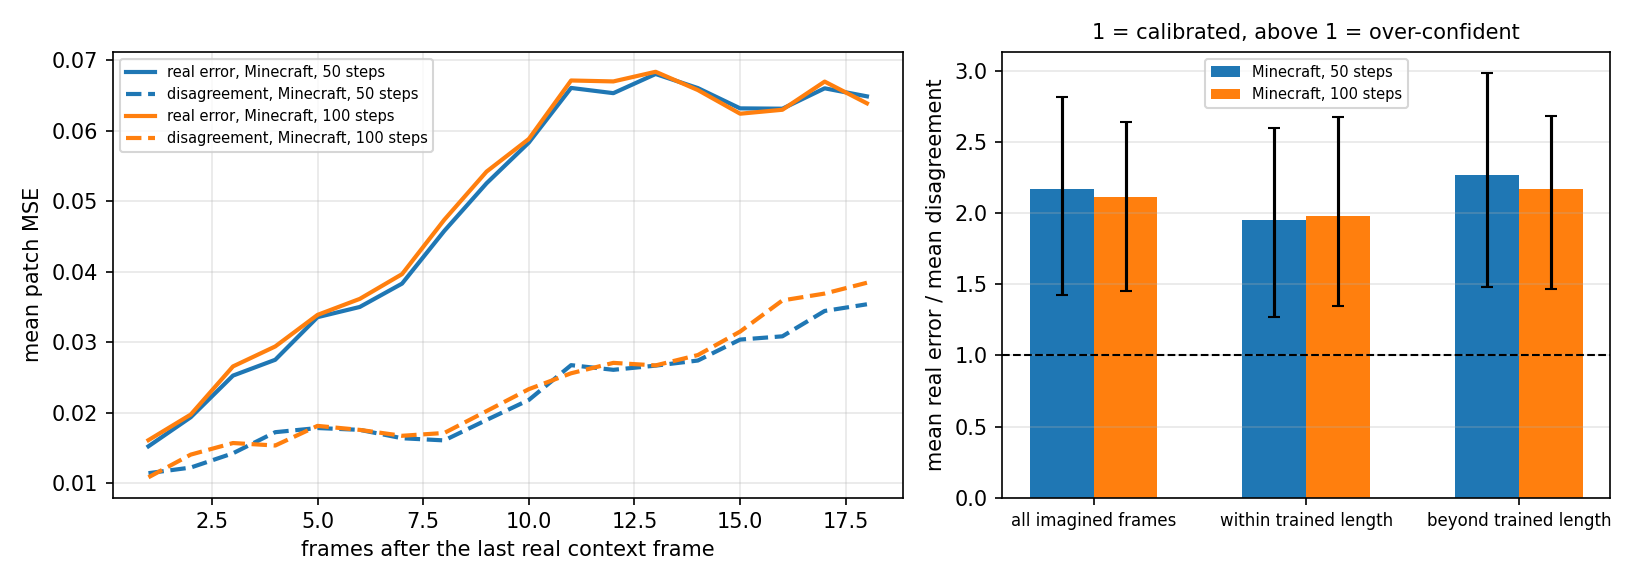

## Minecraft, 50 steps

40 clips from 10 videos x 3 rollouts; 18 imagined frames after 2 real context frames; 16 patches per frame, 1 inspected. Predictors fit on 'Minecraft, 50 steps', leaving the evaluated video out. 95% CIs resample whole videos.

| Audit (1 real patch per frame) | Relative error (%) | 95% CI | Variance vs uniform | 95% CI | Equivalent budget | Max bias (%) |
|---|---|---|---|---|---|---|
| Uniform (Horvitz-Thompson) | 35.0 | 33.4-36.6 | 1.00 | 1.00-1.00 | x1.00 | 0.0e+00 |
| Uniform + CV[visual] | 30.2 | 28.5-32.0 | 0.74 | 0.69-0.82 | x1.34 | 1.3e-14 |
| Smart + CV[visual] | 29.8 | 28.2-31.5 | 0.73 | 0.66-0.80 | x1.38 | 2.1e-14 |
| Negative control: CV[shuffled proxies] | 35.1 | 33.5-36.7 | 1.01 | 1.00-1.01 | x0.99 | 1.4e-14 |
| Uniform + CV[visual+disagreement] | 28.8 | 27.4-30.2 | 0.68 | 0.62-0.73 | x1.48 | 1.4e-14 |
| Smart + CV[visual+disagreement] | 31.6 | 28.6-35.1 | 0.81 | 0.66-1.01 | x1.23 | 4.2e-14 |
| Smart + CV[visual+disagreement], 2 rollouts | 31.0 | 28.2-34.5 | 0.78 | 0.64-0.97 | x1.27 | 3.3e-14 |
| Oracle Neyman (not deployable) | 15.0 | 14.0-15.9 | 0.18 | 0.16-0.22 | x5.41 | 2.3e-14 |

**Self-assessment versus audit**

| Frames | Estimator | Signed bias (%) [95% CI] | Relative error (%) [95% CI] |
|---|---|---|---|
| all imagined frames | Visual predictor (no real data) | +47.1 (+20.6 to +75.7) | 103.5 (73.8-129.7) |
| all imagined frames | Rollout disagreement (no real data) | -32.5 (-44.8 to -18.5) | 54.9 (49.7-59.7) |
| all imagined frames | Calibrated predictor (visual+disagreement) (no real data) | +41.3 (+16.8 to +67.0) | 90.3 (65.7-112.4) |
| all imagined frames | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 31.6 (28.6-35.1) |
| within trained length | Visual predictor (no real data) | +61.0 (+20.2 to +108.0) | 139.5 (84.0-186.6) |
| within trained length | Rollout disagreement (no real data) | -28.1 (-42.2 to -14.3) | 52.4 (44.4-59.4) |
| within trained length | Calibrated predictor (visual+disagreement) (no real data) | +55.2 (+17.0 to +96.2) | 121.4 (77.5-158.0) |
| within trained length | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 81.0 (57.2-104.3) |
| beyond trained length | Visual predictor (no real data) | +55.1 (+29.3 to +84.1) | 113.8 (87.4-139.3) |
| beyond trained length | Rollout disagreement (no real data) | -30.8 (-43.1 to -16.6) | 57.3 (50.3-64.8) |
| beyond trained length | Calibrated predictor (visual+disagreement) (no real data) | +47.5 (+24.6 to +71.9) | 98.7 (76.2-119.4) |
| beyond trained length | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 33.2 (31.6-35.0) |

**Calibration of the model's disagreement** (slope of real error on disagreement; 1 = calibrated, >1 = over-confident)

| Frames | Slope | 95% CI | Mean error / mean disagreement | 95% CI | Spearman |
|---|---|---|---|---|---|
| all imagined frames | 1.09 | 0.97-1.27 | 1.85 | 1.47-2.35 | 0.75 |
| within trained length | 1.13 | 0.99-1.43 | 1.81 | 1.41-2.33 | 0.81 |
| beyond trained length | 1.08 | 0.97-1.26 | 1.87 | 1.49-2.38 | 0.70 |

**Rollouts versus real patches** (relative error %, all imagined frames)

| Configuration | 1 patch/frame | 2 patches/frame | 3 patches/frame | 4 patches/frame |
|---|---|---|---|---|
| 1 rollout, uniform | 35.0 (33.4-36.6) | 24.8 (23.6-25.9) | 20.2 (19.3-21.1) | 17.5 (16.7-18.3) |
| 1 rollout, smart + CV[visual] | 29.8 (28.2-31.5) | 21.1 (20.0-22.3) | 17.2 (16.3-18.2) | 14.9 (14.1-15.7) |
| 2 rollouts, smart + CV[visual+disagreement] | 31.0 (28.2-34.5) | 21.9 (19.9-24.4) | 17.9 (16.3-19.9) | 15.5 (14.1-17.3) |
| 3 rollouts, smart + CV[visual+disagreement] | 31.6 (28.6-35.1) | 22.3 (20.3-24.8) | 18.2 (16.5-20.3) | 15.8 (14.3-17.6) |


## Minecraft, 100 steps

16 clips from 10 videos x 3 rollouts; 18 imagined frames after 2 real context frames; 16 patches per frame, 1 inspected. Predictors fit on 'Minecraft, 100 steps', leaving the evaluated video out. 95% CIs resample whole videos.

| Audit (1 real patch per frame) | Relative error (%) | 95% CI | Variance vs uniform | 95% CI | Equivalent budget | Max bias (%) |
|---|---|---|---|---|---|---|
| Uniform (Horvitz-Thompson) | 35.0 | 32.7-37.5 | 1.00 | 1.00-1.00 | x1.00 | 0.0e+00 |
| Uniform + CV[visual] | 29.2 | 26.8-31.7 | 0.70 | 0.58-0.80 | x1.43 | 1.4e-14 |
| Smart + CV[visual] | 29.7 | 27.2-32.1 | 0.72 | 0.59-0.84 | x1.39 | 2.3e-14 |
| Negative control: CV[shuffled proxies] | 35.1 | 32.8-37.6 | 1.00 | 1.00-1.01 | x1.00 | 1.1e-14 |
| Uniform + CV[visual+disagreement] | 27.5 | 24.5-30.4 | 0.62 | 0.47-0.75 | x1.61 | 9.4e-15 |
| Smart + CV[visual+disagreement] | 29.3 | 25.6-32.4 | 0.70 | 0.52-0.88 | x1.43 | 1.7e-14 |
| Smart + CV[visual+disagreement], 2 rollouts | 29.3 | 26.1-32.2 | 0.70 | 0.54-0.87 | x1.42 | 2.0e-14 |
| Oracle Neyman (not deployable) | 15.5 | 14.0-16.9 | 0.20 | 0.16-0.23 | x5.10 | 1.9e-14 |

**Self-assessment versus audit**

| Frames | Estimator | Signed bias (%) [95% CI] | Relative error (%) [95% CI] |
|---|---|---|---|
| all imagined frames | Visual predictor (no real data) | +50.4 (+0.8 to +107.1) | 103.7 (66.9-137.2) |
| all imagined frames | Rollout disagreement (no real data) | -36.8 (-53.0 to -15.6) | 50.8 (39.6-59.2) |
| all imagined frames | Calibrated predictor (visual+disagreement) (no real data) | +47.2 (-0.6 to +104.0) | 99.0 (61.1-136.4) |
| all imagined frames | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 29.3 (25.6-32.4) |
| within trained length | Visual predictor (no real data) | +91.2 (+0.7 to +197.5) | 197.3 (56.3-286.4) |
| within trained length | Rollout disagreement (no real data) | -29.7 (-55.4 to -1.1) | 59.5 (50.6-67.4) |
| within trained length | Calibrated predictor (visual+disagreement) (no real data) | +88.3 (-3.0 to +194.3) | 191.5 (48.9-281.4) |
| within trained length | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 66.2 (49.2-85.3) |
| beyond trained length | Visual predictor (no real data) | +53.0 (+4.6 to +111.3) | 109.2 (73.5-144.9) |
| beyond trained length | Rollout disagreement (no real data) | -35.1 (-52.2 to -12.4) | 51.9 (40.4-60.1) |
| beyond trained length | Calibrated predictor (visual+disagreement) (no real data) | +48.9 (+3.2 to +105.4) | 103.2 (67.7-138.1) |
| beyond trained length | Audit: Smart + CV[visual+disagreement], 1 patch | 0 (exact) | 34.4 (29.0-39.1) |

**Calibration of the model's disagreement** (slope of real error on disagreement; 1 = calibrated, >1 = over-confident)

| Frames | Slope | 95% CI | Mean error / mean disagreement | 95% CI | Spearman |
|---|---|---|---|---|---|
| all imagined frames | 1.22 | 1.00-1.38 | 2.11 | 1.45-2.64 | 0.71 |
| within trained length | 1.32 | 1.02-1.64 | 1.98 | 1.35-2.68 | 0.80 |
| beyond trained length | 1.19 | 0.99-1.34 | 2.17 | 1.46-2.69 | 0.63 |

**Rollouts versus real patches** (relative error %, all imagined frames)

| Configuration | 1 patch/frame | 2 patches/frame | 3 patches/frame | 4 patches/frame |
|---|---|---|---|---|
| 1 rollout, uniform | 35.0 (32.7-37.5) | 24.7 (23.2-26.5) | 20.2 (18.9-21.7) | 17.5 (16.4-18.8) |
| 1 rollout, smart + CV[visual] | 29.7 (27.2-32.1) | 21.0 (19.3-22.7) | 17.1 (15.7-18.5) | 14.9 (13.6-16.0) |
| 2 rollouts, smart + CV[visual+disagreement] | 29.3 (26.1-32.2) | 20.7 (18.4-22.8) | 16.9 (15.0-18.6) | 14.7 (13.0-16.1) |
| 3 rollouts, smart + CV[visual+disagreement] | 29.3 (25.6-32.4) | 20.7 (18.1-22.9) | 16.9 (14.8-18.7) | 14.6 (12.8-16.2) |


## Findings

- **Uniform + CV[visual]**: variance x0.74 of uniform (95% CI 0.69-0.82), the accuracy of 1.34 uniform patches per frame. Reduction is statistically clear.
- **Smart + CV[visual]**: variance x0.73 of uniform (95% CI 0.66-0.80), the accuracy of 1.38 uniform patches per frame. Reduction is statistically clear.
- **Negative control: CV[shuffled proxies]**: variance x1.01 of uniform (95% CI 1.00-1.01), the accuracy of 0.99 uniform patches per frame. Not distinguishable from uniform.
- **Uniform + CV[visual+disagreement]**: variance x0.68 of uniform (95% CI 0.62-0.73), the accuracy of 1.48 uniform patches per frame. Reduction is statistically clear.
- **Smart + CV[visual+disagreement]**: variance x0.81 of uniform (95% CI 0.66-1.01), the accuracy of 1.23 uniform patches per frame. Not distinguishable from uniform.
- **Smart + CV[visual+disagreement], 2 rollouts**: variance x0.78 of uniform (95% CI 0.64-0.97), the accuracy of 1.27 uniform patches per frame. Reduction is statistically clear.
- **Rollouts versus patches**: with 3 rollouts and 1 patch per frame the audit is as accurate as a single-rollout audit with 0.89 patches per frame (95% CI 0.79-1.03). Variance of 3 rollouts + 1 patch relative to 1 rollout + 2 patches: 2.24 (1.95-2.54).
- **Minecraft, 50 steps, all imagined frames, Rollout disagreement**: bias -32.5% (-44.8 to -18.5), CI excludes zero.
- **Minecraft, 50 steps, all imagined frames, Calibrated predictor (visual+disagreement)**: bias +41.3% (+16.8 to +67.0), CI excludes zero.
- **Minecraft, 50 steps, within trained length, Rollout disagreement**: bias -28.1% (-42.2 to -14.3), CI excludes zero.
- **Minecraft, 50 steps, within trained length, Calibrated predictor (visual+disagreement)**: bias +55.2% (+17.0 to +96.2), CI excludes zero.
- **Minecraft, 50 steps, beyond trained length, Rollout disagreement**: bias -30.8% (-43.1 to -16.6), CI excludes zero.
- **Minecraft, 50 steps, beyond trained length, Calibrated predictor (visual+disagreement)**: bias +47.5% (+24.6 to +71.9), CI excludes zero.
- **Minecraft, 100 steps, all imagined frames, Rollout disagreement**: bias -36.8% (-53.0 to -15.6), CI excludes zero.
- **Minecraft, 100 steps, all imagined frames, Calibrated predictor (visual+disagreement)**: bias +47.2% (-0.6 to +104.0), CI includes zero.
- **Minecraft, 100 steps, within trained length, Rollout disagreement**: bias -29.7% (-55.4 to -1.1), CI excludes zero.
- **Minecraft, 100 steps, within trained length, Calibrated predictor (visual+disagreement)**: bias +88.3% (-3.0 to +194.3), CI includes zero.
- **Minecraft, 100 steps, beyond trained length, Rollout disagreement**: bias -35.1% (-52.2 to -12.4), CI excludes zero.
- **Minecraft, 100 steps, beyond trained length, Calibrated predictor (visual+disagreement)**: bias +48.9% (+3.2 to +105.4), CI excludes zero.
- **Unbiasedness**: the exact expectation of every audit equals the truth to numerical precision (max bias column), in every condition and horizon, including the negative control.


In [13]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RESULTS}/steps_check.md").read()))
display(Markdown("**Figure 7. Real error and disagreement with 50 and 100 sampling steps (same clips)**"))
display(Image(filename=f"{RESULTS}/fig7_sampling_steps.png", width=900))
display(Markdown(open(f"{RESULTS}/results.md").read()))

## 8. Export

In [14]:
shutil.copytree(LOGS, f"{RESULTS}/generation_logs", dirs_exist_ok=True)
shutil.copy(AUDIT, RESULTS)
shutil.copy(f"{REPO}/df_dump_run.py", RESULTS)
shutil.copy(f"{DUMP_ROOT}/plan.json", RESULTS)
archive = shutil.make_archive(f"{WORK}/wm_audit_steps_results", "zip", RESULTS)
size = sum(os.path.getsize(f) for f in glob.glob(f"{DUMP_ROOT}/**/*.npz", recursive=True)) / 2**20
print("results:", archive)
print(f"raw rollouts kept in: {DUMP_ROOT} ({size:.0f} MB)")
print(f"total notebook time: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")

results: /kaggle/working/wm_audit_steps_results.zip
raw rollouts kept in: /kaggle/working/wm_audit_data (353 MB)
total notebook time: 3.86 h
